# **fMRS disparity: load, visualize, clean and save for fslmrs data**
### Betina Ip May 2024 Oxford

## This script is set up to
#### 1) load data from the fit output directory from FSL-MRS 
#### 2) load fitted MRS data analysed using fsl-mrs from user home directory
#### 3) identify outliers in metabolite concentrations using 1.5 IQR
#### 4) remove outliers and associated SNR measures, saves both cleaned and raw data
#### 5) report number of excluded data points (including missing data point due to a priori unusable/uncollected data )
#### 6) save dataframe as csv file under filepath for processing in the next jupyter notebook


## **First, set up environment and your paths where the raw data is located**

In [1]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from glob import glob
import numpy as np
import os
from scipy import stats
import warnings; warnings.filterwarnings("ignore")
from pathlib import Path  
from pingouin import corr
import pingouin as pg #pip install pingouin
import string


### **Pathnames**: you need to replace the pathnames with your own directory paths

In [2]:
datadir           = '/vols/Scratch/ifanip/fmrs_disparity/derivatives'
derivatives_dir   = datadir


### **Key variables**: sets up name of FSL-MRS fit directory to use, metabolite unit and the filename of the output.csv file

In [3]:
# Used output directories
versions =        '30May2024'                # difference spectrum fit, with tissue fraction correction 

# Choose the metabolite quantification method
# conc_est = 'mMol_kg' # used for file

which_unit = 'mMol/kg'# used for loading data
conc_est = 'mMol_kg' #  used for csv file name

# Output file names.
filepath2 = Path('/home/fs0/ifanip/scratch/fmrs_disparity/derivatives/fmrsdisparity_' + versions + '_' + conc_est)  
filepath2.parent.mkdir(parents=True, exist_ok=True)  


### Here I define a few functions to load all data types. Make sure they match your file names.

In [4]:
subjects          = sorted([f.split('/')[-1] for f in glob( os.path.join(datadir,'sub-???') )])
ROI   = 'V1'
conditions        = ['rest','corr','anti']

In [5]:
def load_mrs(sub,cond,ROI,metab,version,which):
    """Load concentration data from csv file
    """
    filename = os.path.join(datadir,f'analysis-{version}',sub,'mrs',ROI,'fit_output',cond,'summary.csv')
    if os.path.exists(filename):
        tmp = pd.read_csv(filename)
        tmp
        return float(tmp.loc[ tmp['Metab']==metab ][which])
    else:
        return np.nan

In [6]:
# load bold change to LOC localiser from featquery directory

def load_bold(sub):
    """Load featquery percentage bold change from txt file
    """
    filename = os.path.join(datadir,sub,'func',f'{sub}_task_derivatives.feat/featquery','report.txt')
    
    if os.path.exists(filename):
        tmp= pd.read_csv(filename, sep = " ",header = None)
        return(float(tmp.loc[0,5])) # print the mean percentage BOLD-change
    else:
        print('not existing')
        

In [8]:
D = {v: [] for v in subjects}

for sub in subjects:
    D[sub].append(load_bold(sub))

bold = pd.DataFrame(D)
bold = bold.T
bold.columns =['bold']
bold = bold.reset_index(drop=True)

In [9]:
D = {v: [] for v in subjects}

for sub in subjects:
    D[sub].append(load_bold_bensonatlas(sub))

bold_benson = pd.DataFrame(D)
bold_benson = bold_benson.T
bold_benson.columns =['bold_benson']
bold_benson = bold_benson.reset_index(drop=True)

## here I load raw output data from summary.csv files in the FSL-MRS fit directory
### we want the concentrations, the abs crlb, the NAA line width for EVC and LOC

In [10]:
#load GABA+ in absolute concentrations for EVC

metab = 'GABA+sysMM'

D = {v:[] for v in conditions}
for sub in subjects:
    values = []
    for cond in conditions:
        D[cond].append(load_mrs(sub,cond,ROI,metab,versions,which_unit) )
        #print(sub,cond, ROI, metab, versions, which_unit) # as a sanity check, report all the variables while executing the loop
v1_gaba =pd.DataFrame(D)
v1_gaba.columns = ['v1_rest','v1_corr','v1_anti']

In [11]:
v1_gaba

,v1_rest,v1_corr,v1_anti
0,4.007791,NaN,NaN
1,3.936353,4.439660,4.123419
2,4.041490,NaN,3.928835
3,3.441669,3.502608,3.389602
4,NaN,3.782540,3.928208
5,3.829921,3.940328,3.716314
6,3.455747,3.687812,3.602091
7,3.907766,3.793371,3.740609
8,3.919488,3.759978,3.966270
9,3.775201,3.671169,3.771669


In [12]:
#load GABA+ in absolute concentrations for LO
ROI = 'LO'
metab = 'GABA+sysMM'

D = {v:[] for v in conditions}
for sub in subjects:
    values = []
    for cond in conditions:
        D[cond].append(load_mrs(sub,cond,ROI,metab,versions,which_unit) )
        #print(sub,cond, ROI, metab, versions, which_unit) # as a sanity check, report all the variables while executing the loop
lo_gaba =pd.DataFrame(D)
lo_gaba.columns = ['lo_rest','lo_corr','lo_anti']

In [13]:
lo_gaba

,lo_rest,lo_corr,lo_anti
0,NaN,3.840095,3.995814
1,3.746709,3.721978,3.686638
2,3.629753,3.746070,3.343720
3,3.402818,3.474657,3.485810
4,NaN,3.862341,3.990287
5,4.387879,4.256086,4.263479
6,4.227413,3.998790,4.277743
7,3.972282,3.838374,3.751325
8,3.924083,3.886287,3.786490
9,3.861680,3.988794,4.063538


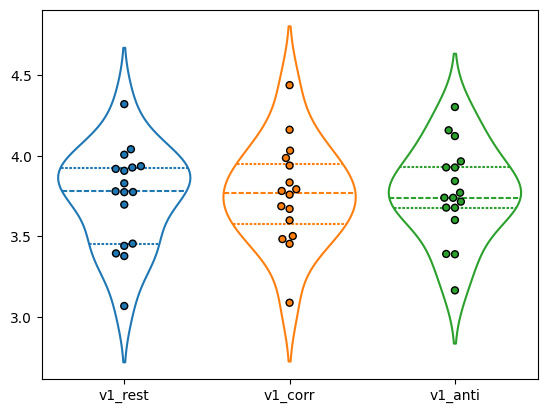

In [14]:
sns.violinplot(v1_gaba, fill = False, inner = "quart")
ax = sns.swarmplot(v1_gaba, edgecolor = 'black', size = 5, linewidth = 1)


In [15]:
# load the linewidth of NAA from diff spectrum for EVC

metab = 'NAA' 
which = 'FWHM'
ROI = 'V1'

FWHM = {v:[] for v in conditions}
for sub in subjects:
    values = []
    for cond in conditions:
        FWHM[cond].append(load_mrs(sub,cond,ROI,metab,versions,which) )
        #print(sub,cond, ROI, metab, versions, which) # as a sanity check, report all the variables while executing the loop

v1_FWHM = pd.DataFrame(FWHM)
v1_FWHM.columns = ['v1_rest_fwhm','v1_corr_fwhm','v1_anti_fwhm']

In [16]:
# The linewidth of NAA from diff spectrum for LO

metab = 'NAA' 
which = 'FWHM'
ROI = 'LO'

FWHM = {v:[] for v in conditions}
for sub in subjects:
    values = []
    for cond in conditions:
        FWHM[cond].append(load_mrs(sub,cond,ROI,metab,versions,which) )
        #print(sub,cond, ROI, metab, versions, which) # as a sanity check, report all the variables while executing the loop

lo_FWHM = pd.DataFrame(FWHM)
lo_FWHM.columns = ['lo_rest_fwhm','lo_corr_fwhm','lo_anti_fwhm']

In [17]:
# load Glx for EVC

metab = 'Glu+Gln+GSH'
ROI='V1'
D = {v:[] for v in conditions}
for sub in subjects:
    values = []
    for cond in conditions:
        D[cond].append(load_mrs(sub,cond,ROI,metab,versions,which_unit) )

v1_glx = pd.DataFrame(D)
v1_glx.columns = ['v1_rest_glx','v1_corr_glx','v1_anti_glx']

In [18]:
# load Glx for LO

metab = 'Glu+Gln+GSH'
ROI='LO'
D = {v:[] for v in conditions}
for sub in subjects:
    values = []
    for cond in conditions:
        D[cond].append(load_mrs(sub,cond,ROI,metab,versions,which_unit) )

lo_glx = pd.DataFrame(D)
lo_glx.columns = ['lo_rest_glx','lo_corr_glx','lo_anti_glx']

In [19]:
# The abs crlb GABA for EVC

metab = 'GABA+sysMM' 
which = 'mMol/kg CRLB'
ROI = 'V1'

crlb = {v:[] for v in conditions}
for sub in subjects:
    values = []
    for cond in conditions:
        crlb[cond].append(load_mrs(sub,cond,ROI,metab,versions,which) )
        #print(sub,cond, ROI, metab, versions, which) # as a sanity check, report all the variables while executing the loop

v1_crlb = pd.DataFrame(crlb)
v1_crlb.columns = ['v1_rest_crlb','v1_corr_crlb','v1_anti_crlb']

In [20]:
# The abs crlb GABA for LO

metab = 'GABA+sysMM' 
which = 'mMol/kg CRLB'
ROI = 'LO'

crlb = {v:[] for v in conditions}
for sub in subjects:
    values = []
    for cond in conditions:
        crlb[cond].append(load_mrs(sub,cond,ROI,metab,versions,which) )
        #print(sub,cond, ROI, metab, versions, which) # as a sanity check, report all the variables while executing the loop

lo_crlb = pd.DataFrame(crlb)
lo_crlb.columns = ['lo_rest_crlb','lo_corr_crlb','lo_anti_crlb']

### **Create dataframe** that contains all different outcome measures into one

In [21]:
df = pd.concat([v1_gaba,lo_gaba,v1_glx,lo_glx, v1_FWHM, lo_FWHM, v1_crlb, lo_crlb,bold,bold_benson],axis = 1, ignore_index = False) 

In [22]:
df

,v1_rest,v1_corr,v1_anti,lo_rest,lo_corr,lo_anti,v1_rest_glx,v1_corr_glx,v1_anti_glx,lo_rest_glx,...,lo_corr_fwhm,lo_anti_fwhm,v1_rest_crlb,v1_corr_crlb,v1_anti_crlb,lo_rest_crlb,lo_corr_crlb,lo_anti_crlb,bold,bold_benson
0,4.007791,NaN,NaN,NaN,3.840095,3.995814,10.126739,NaN,NaN,NaN,...,6.205115,6.248461,0.237577,NaN,NaN,NaN,0.221780,0.218766,0.9484,0.77210
1,3.936353,4.439660,4.123419,3.746709,3.721978,3.686638,9.197447,11.078219,10.543814,8.642300,...,5.979256,6.002973,0.217657,0.239497,0.248448,0.190506,0.198685,0.189914,0.5078,0.02501
2,4.041490,NaN,3.928835,3.629753,3.746070,3.343720,9.438617,NaN,9.547595,7.898324,...,7.495874,7.588825,0.207693,NaN,0.198856,0.181170,0.205935,0.169302,0.6523,0.35750
3,3.441669,3.502608,3.389602,3.402818,3.474657,3.485810,9.258849,9.957297,10.053688,8.142039,...,6.338205,6.640252,0.201809,0.151306,0.194095,0.147301,0.150146,0.141932,0.4731,0.18880
4,NaN,3.782540,3.928208,NaN,3.862341,3.990287,NaN,10.588518,10.283455,NaN,...,5.446501,5.430613,NaN,0.207635,0.224353,NaN,0.199599,0.165169,1.0900,0.49830
5,3.829921,3.940328,3.716314,4.387879,4.256086,4.263479,8.021384,11.390492,8.308176,11.949694,...,5.635241,5.713200,0.203984,0.202320,0.201294,0.248693,0.238064,0.239116,0.3087,0.33880
6,3.455747,3.687812,3.602091,4.227413,3.998790,4.277743,9.125100,9.417879,9.329788,9.839951,...,5.590442,5.778146,0.147142,0.196642,0.193580,0.224331,0.209373,0.232017,0.8849,0.73570
7,3.907766,3.793371,3.740609,3.972282,3.838374,3.751325,10.222248,9.997932,11.364045,10.022122,...,5.661697,5.993277,0.232505,0.182737,0.252779,0.199794,0.227511,0.213055,0.7213,0.57120
8,3.919488,3.759978,3.966270,3.924083,3.886287,3.786490,9.711464,10.163042,8.794798,9.905679,...,6.415734,6.463032,0.173313,0.222175,0.189348,0.220656,0.210886,0.213069,0.4534,0.08892
9,3.775201,3.671169,3.771669,3.861680,3.988794,4.063538,9.365338,9.553782,8.980989,9.887729,...,5.619225,5.874296,0.211817,0.210480,0.211730,0.208894,0.205254,0.223659,0.7740,-0.04083


### **Defining functions** clean from 1.5 IQR outliers and display data

In [23]:
def iqr_outlier(df,col,rng,name):
    q75,q25 = np.nanpercentile(df[col],[75,25])
    intr_qr = q75-q25
    
    max = q75+(rng* intr_qr)
    min = q25-(rng* intr_qr)
    
    df[name] = df[col]
    
    df.loc[df[col] > max, name] = np.nan
    df.loc[df[col] < min, name] = np.nan

In [24]:
# Set to NAN values that are matched by an outlier value in the NAA column in cleaned data column '_exout'
def exclude_byreference(df, outlier, columns):
    for cond in columns:
        df[cond].mask(outlier, other=np.nan, inplace=True)

In [25]:
def boxplot_amb(dat,conditions,title,ylab,xlab,ax_id):
    sns.boxplot(data=dat[conditions],linewidth=2,orient="v", ax=ax[ax_id]).set(title=title)
    sns.stripplot(data=dat[conditions],color=".2", ax=ax[ax_id])
    ax[ax_id].set_ylabel(ylab,fontsize=20)
    ax[ax_id].set_xticklabels(xlab)
    fig.show()                        

### Apply the exclusions from the main metabolites to supporting measure to bring them into synch
Removes outlier using 1.5 interquartile range by setting to nan
Removes metabolite data points that have outlier by setting the outlier to NAA values in a new column _exout

In [26]:
dat_frame = df

#Set to Nan values that are outside of 1.5 inter-quartile range for any column

# identify outliers for GABA and create new column
iqr_outlier(dat_frame,'v1_rest',1.5,'v1_rest_exout')
iqr_outlier(dat_frame,'v1_corr',1.5,'v1_corr_exout')
iqr_outlier(dat_frame,'v1_anti',1.5,'v1_anti_exout')

iqr_outlier(dat_frame,'lo_rest',1.5,'lo_rest_exout')
iqr_outlier(dat_frame,'lo_corr',1.5,'lo_corr_exout')
iqr_outlier(dat_frame,'lo_anti',1.5,'lo_anti_exout')

iqr_outlier(dat_frame,'v1_rest_glx',1.5,'v1_rest_glx_exout')
iqr_outlier(dat_frame,'v1_corr_glx',1.5,'v1_corr_glx_exout')
iqr_outlier(dat_frame,'v1_anti_glx',1.5,'v1_anti_glx_exout')

iqr_outlier(dat_frame,'lo_rest_glx',1.5,'lo_rest_glx_exout')
iqr_outlier(dat_frame,'lo_corr_glx',1.5,'lo_corr_glx_exout')
iqr_outlier(dat_frame,'lo_anti_glx',1.5,'lo_anti_glx_exout')


#### There are many supporting measures, that are linked to the metabolite concentrations. These have to be streamlined to what was excluded. So here I set to NAN the values that are matched by an outlier value in the chosen column in cleaned data column '_exout'
def exclude_byreference(df, outlier, columns):
    for cond in columns:
        df[cond].mask(outlier, other=np.nan, inplace=True)

In [27]:
# For each condition, use column and set corresponding metabolite values to NAN. Use as many columns as needed.
# It's a bit clumsy, but you first need to copy the non-outlier excluded spporting measures data to a new column called _exout before the excluded valuse are set to NaN.

# For V1
dat_frame['v1_rest_crlb_exout'] = dat_frame['v1_rest_crlb']
dat_frame['v1_corr_crlb_exout'] = dat_frame['v1_corr_crlb']
dat_frame['v1_anti_crlb_exout'] = dat_frame['v1_anti_crlb']

dat_frame['v1_rest_fwhm_exout'] = dat_frame['v1_rest_fwhm']
dat_frame['v1_corr_fwhm_exout'] = dat_frame['v1_corr_fwhm']
dat_frame['v1_anti_fwhm_exout'] = dat_frame['v1_anti_fwhm']


# For LO
dat_frame['lo_rest_crlb_exout'] = dat_frame['lo_rest_crlb']
dat_frame['lo_corr_crlb_exout'] = dat_frame['lo_corr_crlb']
dat_frame['lo_anti_crlb_exout'] = dat_frame['lo_anti_crlb']

dat_frame['lo_rest_fwhm_exout'] = dat_frame['lo_rest_fwhm']
dat_frame['lo_corr_fwhm_exout'] = dat_frame['lo_corr_fwhm']
dat_frame['lo_anti_fwhm_exout'] = dat_frame['lo_anti_fwhm']


#### **Applying outlier exclusions to supporting measures**

In [28]:

outlier = np.isnan(dat_frame.v1_rest_exout) # this is the reference column
exclude_byreference(dat_frame,outlier,['v1_rest_crlb_exout'])
exclude_byreference(dat_frame,outlier,['v1_rest_fwhm_exout'])

outlier = np.isnan(dat_frame.v1_corr_exout) # this is the reference column
exclude_byreference(dat_frame,outlier,['v1_corr_crlb_exout'])
exclude_byreference(dat_frame,outlier,['v1_corr_fwhm_exout'])

outlier = np.isnan(dat_frame.v1_rest_exout) # this is the reference column
exclude_byreference(dat_frame,outlier,['v1_anti_crlb_exout'])
exclude_byreference(dat_frame,outlier,['v1_anti_fwhm_exout'])


outlier = np.isnan(dat_frame.lo_rest_exout) # this is the reference column
exclude_byreference(dat_frame,outlier,['lo_rest_crlb_exout'])
exclude_byreference(dat_frame,outlier,['lo_rest_fwhm_exout'])

outlier = np.isnan(dat_frame.v1_corr_exout) # this is the reference column
exclude_byreference(dat_frame,outlier,['lo_corr_crlb_exout'])
exclude_byreference(dat_frame,outlier,['lo_corr_fwhm_exout'])

outlier = np.isnan(dat_frame.v1_rest_exout) # this is the reference column
exclude_byreference(dat_frame,outlier,['lo_anti_crlb_exout'])
exclude_byreference(dat_frame,outlier,['lo_anti_fwhm_exout'])



## Generate E/I measure

In [29]:
dat_frame['v1_rest_ei_exout']=dat_frame['v1_rest_glx_exout']/dat_frame['v1_rest_exout']
dat_frame['v1_corr_ei_exout']=dat_frame['v1_corr_glx_exout']/dat_frame['v1_corr_exout']
dat_frame['v1_anti_ei_exout']=dat_frame['v1_anti_glx_exout']/dat_frame['v1_anti_exout']

dat_frame['lo_rest_ei_exout']=dat_frame['lo_rest_glx_exout']/dat_frame['lo_rest_exout']
dat_frame['lo_corr_ei_exout']=dat_frame['lo_corr_glx_exout']/dat_frame['lo_corr_exout']
dat_frame['lo_anti_ei_exout']=dat_frame['lo_anti_glx_exout']/dat_frame['lo_anti_exout']

## Count the number of NaN values in each condition

In [30]:
#dat_frame_2 =dat_frame.drop(labels=range(28, 37), axis=0)
print(dat_frame[["v1_rest_exout"]].isna().sum())
print(dat_frame[["v1_anti_exout"]].isna().sum())
print(dat_frame[["v1_corr_exout"]].isna().sum())
print(dat_frame[["lo_rest_exout"]].isna().sum())
print(dat_frame[["lo_anti_exout"]].isna().sum())
print(dat_frame[["lo_corr_exout"]].isna().sum())


print(dat_frame[["v1_rest_glx_exout"]].isna().sum())
print(dat_frame[["v1_anti_glx_exout"]].isna().sum())
print(dat_frame[["v1_corr_glx_exout"]].isna().sum())
print(dat_frame[["lo_rest_glx_exout"]].isna().sum())
print(dat_frame[["lo_anti_glx_exout"]].isna().sum())
print(dat_frame[["lo_corr_glx_exout"]].isna().sum())

v1_rest_exout    1
dtype: int64
v1_anti_exout    2
dtype: int64
v1_corr_exout    2
dtype: int64
lo_rest_exout    2
dtype: int64
lo_anti_exout    0
dtype: int64
lo_corr_exout    1
dtype: int64
v1_rest_glx_exout    1
dtype: int64
v1_anti_glx_exout    1
dtype: int64
v1_corr_glx_exout    3
dtype: int64
lo_rest_glx_exout    3
dtype: int64
lo_anti_glx_exout    2
dtype: int64
lo_corr_glx_exout    2
dtype: int64


# MRS QUALITY MEASURES: copy into main manuscript for Table 1

In [31]:
dat_frame[['v1_rest_fwhm_exout','v1_corr_fwhm_exout','v1_anti_fwhm_exout','lo_rest_fwhm_exout','lo_corr_fwhm_exout','lo_anti_fwhm_exout']].describe().loc[['count','mean','std']].round(2).T


,count,mean,std
v1_rest_fwhm_exout,17.0,5.37,0.47
v1_corr_fwhm_exout,16.0,5.31,0.52
v1_anti_fwhm_exout,16.0,5.34,0.48
lo_rest_fwhm_exout,16.0,6.11,0.49
lo_corr_fwhm_exout,16.0,5.97,0.41
lo_anti_fwhm_exout,17.0,6.09,0.50


In [32]:

dat_frame[['v1_rest_crlb_exout','v1_corr_crlb_exout','v1_anti_crlb_exout','lo_rest_crlb_exout','lo_corr_crlb_exout','lo_anti_crlb_exout']].describe().loc[['count','mean','std']].round(2).T


,count,mean,std
v1_rest_crlb_exout,17.0,0.21,0.03
v1_corr_crlb_exout,16.0,0.21,0.03
v1_anti_crlb_exout,16.0,0.21,0.02
lo_rest_crlb_exout,16.0,0.21,0.03
lo_corr_crlb_exout,16.0,0.21,0.02
lo_anti_crlb_exout,17.0,0.21,0.03


### generate csv file for R analysis using LMM

In [33]:
v1rest = dat_frame[['v1_rest_glx_exout','v1_rest_exout','v1_rest_fwhm_exout','v1_rest_crlb_exout','v1_rest_ei_exout']]
v1rest['Voxel']='EVC'
v1rest['Cond']='Rest'
v1rest.columns=['glx','gaba','fwhm','crlb','ei','Voxel','Cond']

v1corr = dat_frame[['v1_corr_glx_exout','v1_corr_exout','v1_corr_fwhm_exout','v1_corr_crlb_exout','v1_corr_ei_exout']]
v1corr['Voxel']='EVC'
v1corr['Cond']='Corr'
v1corr.columns=['glx','gaba','fwhm','crlb','ei','Voxel','Cond']

v1anti = dat_frame[['v1_anti_glx_exout','v1_anti_exout','v1_anti_fwhm_exout','v1_anti_crlb_exout','v1_anti_ei_exout']]
v1anti['Voxel']='EVC'
v1anti['Cond']='Anti'
v1anti.columns=['glx','gaba','fwhm','crlb','ei','Voxel','Cond']


lorest = dat_frame[['lo_rest_glx_exout','lo_rest_exout','lo_rest_fwhm_exout','lo_rest_crlb_exout','lo_rest_ei_exout']]
lorest['Voxel']='LO'
lorest['Cond']='Rest'
lorest.columns=['glx','gaba','fwhm','crlb','ei','Voxel','Cond']

locorr = dat_frame[['lo_corr_glx_exout','lo_corr_exout','lo_corr_fwhm_exout','lo_corr_crlb_exout','lo_corr_ei_exout']]
locorr['Voxel']='LO'
locorr['Cond']='Corr'
locorr.columns=['glx','gaba','fwhm','crlb','ei','Voxel','Cond']

loanti = dat_frame[['lo_anti_glx_exout','lo_anti_exout','lo_anti_fwhm_exout','lo_anti_crlb_exout','lo_anti_ei_exout']]
loanti['Voxel']='LO'
loanti['Cond']='Anti'
loanti.columns=['glx','gaba','fwhm','crlb','ei','Voxel','Cond']

dat = pd.concat([v1rest,v1corr,v1anti,lorest,locorr,loanti],axis =0)
dat.to_csv('/vols/Scratch/ifanip/fmrs_disparity/derivatives/results/fmrsdisparity_gaba.csv')

<Axes: xlabel='Cond', ylabel='crlb'>

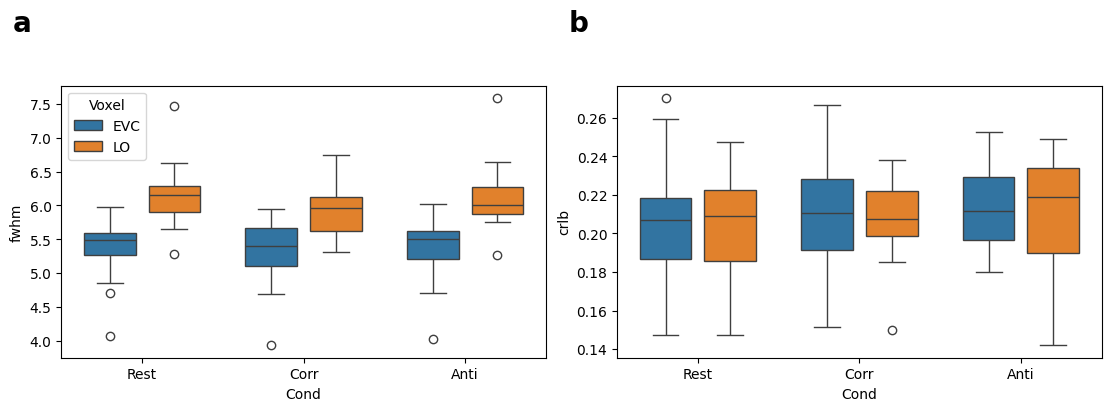

In [34]:
fig, ax =plt.subplots(1,2, figsize = (11,4),constrained_layout=True)

for n, axx in enumerate(ax):
    axx.text(-0.1, 1.2, string.ascii_lowercase[n], transform=axx.transAxes, 
            size=20, weight='bold')
    
dat_nona= dat.dropna()

sns.boxplot(y = dat_nona['fwhm'],
            x = dat_nona['Cond'], 
            hue = dat_nona['Voxel'],
            ax = ax[0],
           gap =0.2,
           
           )

            
sns.boxplot(y = dat_nona['crlb'],
            x = dat_nona['Cond'], 
            hue = dat_nona['Voxel'],
            ax = ax[1],
            legend = '',
           gap =0.2,
           )


In [35]:
dat = pd.concat([v1rest,v1corr,v1anti],axis =0)
dat.to_csv('/vols/Scratch/ifanip/fmrs_disparity/derivatives/results/fmrsdisparity_v1.csv')
dat = pd.concat([lorest,locorr,loanti],axis =0)
dat.to_csv('/vols/Scratch/ifanip/fmrs_disparity/derivatives/results/fmrsdisparity_lo.csv')

# Main result figure: plot voxel x conditions

In [36]:
def barplots(data,cols,title,col_n,xlim,ylim,xlab_n,ylab_n,ax_h,col):
    ax_handle=(ax_h)
    d = data[cols]
    d.columns=col_n

    fsize=12

    ax[ax_handle].spines['right'].set_visible(False)
    ax[ax_handle].spines['top'].set_visible(False)
    ax[ax_handle].spines['left'].set_visible(True)
    ax[ax_handle].spines['bottom'].set_visible(True)
    ylim=ylim
    xlim=xlim
    ylab_name = title
    xlab_name = 'Conditions'
    ax[ax_handle].set_ylabel(ylab_n, fontweight = 'bold', fontsize = fsize)
    ax[ax_handle].set_xlabel(xlab_n, fontweight = 'bold',fontsize = fsize)
    ax[ax_handle].set_title(title, fontweight = 'bold')
    ax[ax_handle].set_ylim(ylim)
    ax[ax_handle].set_xlim(xlim)
    ax[ax_handle].set_ylabel(ylab_n, fontweight = 'bold', fontsize = fsize)
    ax[ax_handle].set_xlabel(xlab_n, fontweight = 'bold',fontsize = fsize)
    sns.barplot(d, width = 0.4, ax = ax[ax_handle],color = col,capsize=0.2,edgecolor='black')
    sns.swarmplot(d, edgecolor = 'black', size = 5, linewidth = 1.5, ax = ax[ax_handle],color='white')




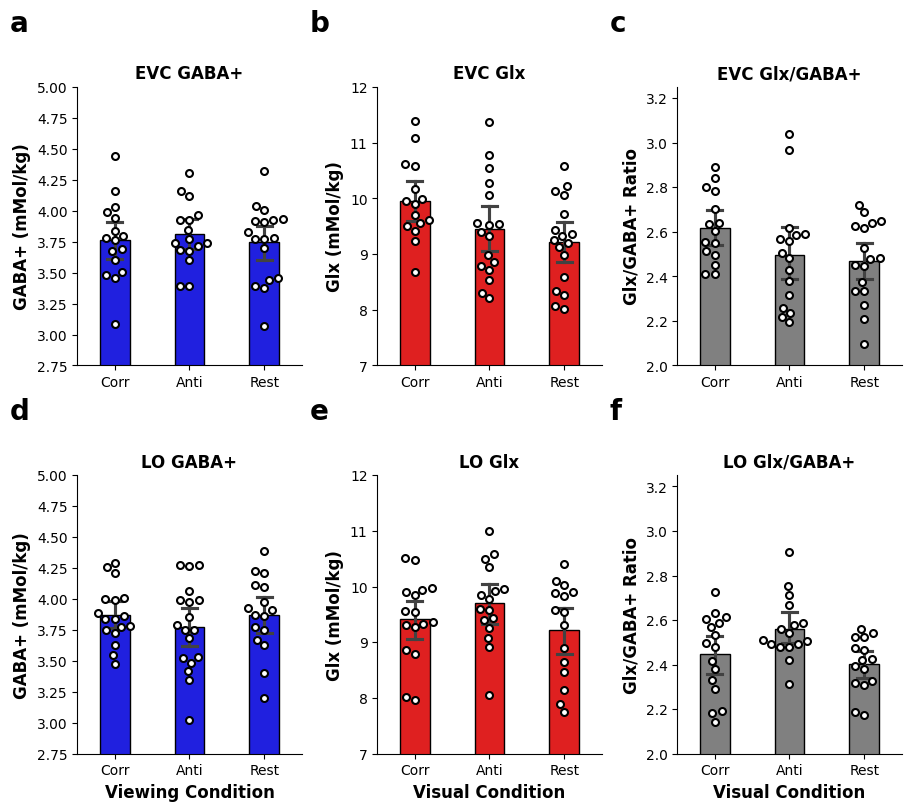

In [37]:
#fig, ax =plt.subplots(2,2, figsize = (8,7),constrained_layout=True)
fig, ax =plt.subplots(2,3, figsize = (9,8),constrained_layout=True)
axi = ax.flat
for n, axx in enumerate(axi):
    axx.text(-0.3, 1.2, string.ascii_lowercase[n], transform=axx.transAxes, 
            size=20, weight='bold')
barplots(dat_frame,["v1_corr_exout","v1_anti_exout","v1_rest_exout"],'EVC GABA+',['Corr','Anti','Rest'],[0,4],[2.75,5],'','GABA+ (mMol/kg)',(0,0),'blue')
barplots(dat_frame,["v1_corr_glx_exout","v1_anti_glx_exout","v1_rest_glx_exout"],'EVC Glx',['Corr','Anti','Rest'],[0,4],[7,12],'','Glx (mMol/kg)',(0,1),'red')
barplots(dat_frame,["v1_corr_ei_exout","v1_anti_ei_exout","v1_rest_ei_exout"],'EVC Glx/GABA+',['Corr','Anti','Rest'],[0,4],[2,3.25],'','Glx/GABA+ Ratio',(0,2),'gray')

barplots(dat_frame,["lo_corr_exout","lo_anti_exout","lo_rest_exout"],'LO GABA+',['Corr','Anti','Rest'],[0,4],[2.75,5],'Viewing Condition','GABA+ (mMol/kg)',(1,0),'blue')
barplots(dat_frame,["lo_corr_glx_exout","lo_anti_glx_exout","lo_rest_glx_exout"],'LO Glx',['Corr','Anti','Rest'],[0,4],[7,12],'Visual Condition','Glx (mMol/kg)',(1,1),'red')
barplots(dat_frame,["lo_corr_ei_exout","lo_anti_ei_exout","lo_rest_ei_exout"],'LO Glx/GABA+',['Corr','Anti','Rest'],[0,4],[2,3.25],'Visual Condition','Glx/GABA+ Ratio',(1,2),'gray')

plt.gca()
plt.savefig('Figure_meanconditions.png',bbox_inches = 'tight')   # save the figure to file
#plt.close()

# Supplementary Figure 1: plot bold vs LOC gaba+ and glx

## define a standard correlation plot 

In [38]:

# add title
# correlationFig(typ,'botheyes_exout','IO_VA_DELTA_TIEW','Both Eyes','namey','Both Eyes','less',(0),'o','cyan',xlims)

def correlationFig(data,xval,yval,xlab_name,ylab_name,title,alt,ax_handle,marker_type,marker_col,xlim,ylim):
    fsize = 12
    sns.set(font_scale = 1)
    sns.set(style = 'white')
    sns.set(style = "ticks")
    #sns.despine(trim = True)
    print (ax_handle)
    data1 = data[[xval,yval]]  # Add control variable for partial correlation

    # First, remove NAN values that are flagged as outliers or missing data

    data_orig = data1.dropna()
        
    ax[ax_handle].title.set_size(14)
    ax[ax_handle].set_ylabel('$\Delta$VA (LogMAR)')
    ax[ax_handle].set_xlabel(xlab_name)
#    ax[ax_handle].set_ylim(0,1.5)
    ax[ax_handle].set_xlim(xlim)
      
    ax[ax_handle].spines['right'].set_visible(False)
    ax[ax_handle].spines['top'].set_visible(False)
    ax[ax_handle].spines['left'].set_visible(True)
    ax[ax_handle].spines['bottom'].set_visible(True)
    
        
    print('normal distribution, using pearson')
    type = 'pearson'
        
    stat = pg.corr(data_orig[xval],data_orig[yval],alternative = alt, method =type)
    print(stat)
    n=stat["n"]
    r=stat["r"].round(2)
    p=stat["p-val"].round(3)
    bf=stat["BF10"]
    bf = bf.astype(float).round(2)

    n=n[type]
    pval = p[type]
    rval = r[type]
    bf = bf[type]
    print('n(',n,')','p=',pval,'r=',rval,type,bf)        
        
    if pval < 0.05:
        # show trend line if correlation is p = 0.05 - 0.1
        sns.regplot(y=data_orig[yval], x=data_orig[xval]
                    , color='black'
                    , ax=ax[ax_handle]
                    ,line_kws={'linewidth':1}
                   ,  scatter=False)
        
        sns.scatterplot(data = data_orig, y=yval, x = xval
                      ,ax=ax[ax_handle]
                      , color=marker_col
                      , marker = marker_type
                      , s = 35
                      #, hue = "TYPE"
                      , legend = False
                      #, style = "TYPE"
                      , palette = [marker_col]
                      , linewidth =0)
    else:

       sns.scatterplot(data = data_orig, y=yval, x = xval
                      ,ax=ax[ax_handle]
                      , color=marker_col
                      , marker = marker_type
                      , s = 35
                      #, hue = "TYPE"
                      , legend = False
                      #, style = "TYPE"
                      , palette = [marker_col]
                      , linewidth =0)
    

  
    # Add the Bayes Factor into the figure title if available (only pearson)
        # Add the Bayes Factor into the figure title if available (only pearson)

    if type == 'pearson':
        #ax[ax_handle].set_title(title + '\n$r$='+str(round(rval,2)) + ', $p$='+ str(round(pval,3)) + '\n$BF_{10}$=' + str(round(bf,2),loc = 'left',fontsize =16, weight = 'bold')
        
        if pval < 0.05:
            ax[ax_handle].set_title(title + '\n$r$='+str(round(rval,2)) +'*'+ ', $BF_{10}$=' + str(bf), fontsize =14, weight = 'bold')
            ax[ax_handle].set_ylabel(ylab_name, fontweight = 'bold', fontsize = fsize)
            ax[ax_handle].set_xlabel(xlab_name, fontweight = 'bold',fontsize = fsize)
            ax[ax_handle].set_ylim(ylim)
            ax[ax_handle].set_xlim(xlim)
            #ax[ax_handle].set_yticks([0,0.25,0.5,0.75,1.0,1.25,1.50])
        else:
            ax[ax_handle].set_title(title + '\n$r$='+str(round(rval,2)) + ', $BF_{10}$=' + str(bf), fontsize =14, weight = 'bold')
            ax[ax_handle].set_ylabel(ylab_name, fontweight = 'bold', fontsize = fsize)
            ax[ax_handle].set_xlabel(xlab_name, fontweight = 'bold',fontsize = fsize)
            ax[ax_handle].set_ylim(ylim)
            ax[ax_handle].set_xlim(xlim)

            #ax[ax_handle].set_yticks([0,0.25,0.5,0.75,1.0,1.25,1.50])

        return n, pval, rval, type, bf



    print('finished')

    

In [39]:

# add title
# correlationFig(typ,'botheyes_exout','IO_VA_DELTA_TIEW','Both Eyes','namey','Both Eyes','less',(0),'o','cyan',xlims)

def correlationFigpartialcor(data,xval,yval,xlab_name,ylab_name,title,alt,ax_handle,marker_type,marker_col,xlim,ylim,ypcor):
    fsize = 12
    sns.set(font_scale = 1)
    sns.set(style = 'white')
    sns.set(style = "ticks")
    #sns.despine(trim = True)
    print (ax_handle)
    print(title)
    data1 = data[[xval,yval,ypcor]]  # Add control variable for partial correlation

    # First, remove NAN values that are flagged as outliers or missing data

    data_orig = data1.dropna()
        
    ax[ax_handle].title.set_size(14)
    ax[ax_handle].set_xlim(xlim)
      
    ax[ax_handle].spines['right'].set_visible(False)
    ax[ax_handle].spines['top'].set_visible(False)
    ax[ax_handle].spines['left'].set_visible(True)
    ax[ax_handle].spines['bottom'].set_visible(True)
    
        
    print('normal distribution, using pearson')
    type = 'pearson'
        
    stat = pg.corr(data_orig[xval],data_orig[yval],alternative = alt, method =type)
    print(stat)
    n=stat["n"]
    r=stat["r"].round(2)
    p=stat["p-val"].round(3)
    bf=stat["BF10"]
    bf = bf.astype(float).round(2)

    n=n[type]
    pval = p[type]
    rval = r[type]
    bf = bf[type]
    print('n(',n,')','p=',pval,'r=',rval,type,bf)        
    print('correcting for spectral quality')

    
    pcor=pg.partial_corr(data=data_orig,x=xval,y=yval,x_covar=ypcor)
    print('*****',pcor)
    if pval < 0.05:
        # show trend line if correlation is p = 0.05 - 0.1
        sns.regplot(y=data_orig[yval], x=data_orig[xval]
                    , color='black'
                    , ax=ax[ax_handle]
                    ,line_kws={'linewidth':1}
                   ,  scatter=False)
        
        sns.scatterplot(data = data_orig, y=yval, x = xval
                      ,ax=ax[ax_handle]
                      , color=marker_col
                      , marker = marker_type
                      , s = 35
                      #, hue = "TYPE"
                      , legend = False
                      #, style = "TYPE"
                      , palette = [marker_col]
                      , linewidth =0)
    else:

       sns.scatterplot(data = data_orig, y=yval, x = xval
                      ,ax=ax[ax_handle]
                      , color=marker_col
                      , marker = marker_type
                      , s = 35
                      #, hue = "TYPE"
                      , legend = False
                      #, style = "TYPE"
                      , palette = [marker_col]
                      , linewidth =0)
    

  
    # Add the Bayes Factor into the figure title if available (only pearson)
        # Add the Bayes Factor into the figure title if available (only pearson)

    if type == 'pearson':
        #ax[ax_handle].set_title(title + '\n$r$='+str(round(rval,2)) + ', $p$='+ str(round(pval,3)) + '\n$BF_{10}$=' + str(round(bf,2),loc = 'left',fontsize =16, weight = 'bold')
        
        if pval < 0.05:
            ax[ax_handle].set_title(title + '\n$r$='+str(round(rval,2)) +'*'+ ', $BF_{10}$=' + str(bf), fontsize =14, weight = 'bold')
            ax[ax_handle].set_ylabel(ylab_name, fontweight = 'bold', fontsize = fsize)
            ax[ax_handle].set_xlabel(xlab_name, fontweight = 'bold',fontsize = fsize)
            ax[ax_handle].set_ylim(ylim)
            ax[ax_handle].set_xlim(xlim)
            #ax[ax_handle].set_yticks([0,0.25,0.5,0.75,1.0,1.25,1.50])
        else:
            ax[ax_handle].set_title(title + '\n$r$='+str(round(rval,2)) + ', $BF_{10}$=' + str(bf), fontsize =14, weight = 'bold')
            ax[ax_handle].set_ylabel(ylab_name, fontweight = 'bold', fontsize = fsize)
            ax[ax_handle].set_xlabel(xlab_name, fontweight = 'bold',fontsize = fsize)
            ax[ax_handle].set_ylim(ylim)
            ax[ax_handle].set_xlim(xlim)

            #ax[ax_handle].set_yticks([0,0.25,0.5,0.75,1.0,1.25,1.50])

        return n, pval, rval, type, bf



    print('finished')

    

(0, 0)
LO Rest
normal distribution, using pearson
          n         r          CI95%     p-val   BF10     power
pearson  15  0.257028  [-0.29, 0.68]  0.355082  0.472  0.154383
n( 15 ) p= 0.355 r= 0.26 pearson 0.47
correcting for spectral quality
*****           n         r          CI95%     p-val
pearson  15  0.130521  [-0.43, 0.62]  0.656505
(0, 1)
LO Corr
normal distribution, using pearson
          n         r          CI95%     p-val   BF10     power
pearson  14  0.340962  [-0.23, 0.74]  0.232874  0.631  0.228261
n( 14 ) p= 0.233 r= 0.34 pearson 0.63
correcting for spectral quality
*****           n        r          CI95%    p-val
pearson  14  0.04828  [-0.52, 0.58]  0.87554
(0, 2)
LO Anti
normal distribution, using pearson
          n        r         CI95%     p-val   BF10     power
pearson  15  0.60631  [0.14, 0.85]  0.016569  4.397  0.706259
n( 15 ) p= 0.017 r= 0.61 pearson 4.4
correcting for spectral quality
*****           n         r          CI95%    p-val
pearson  15  

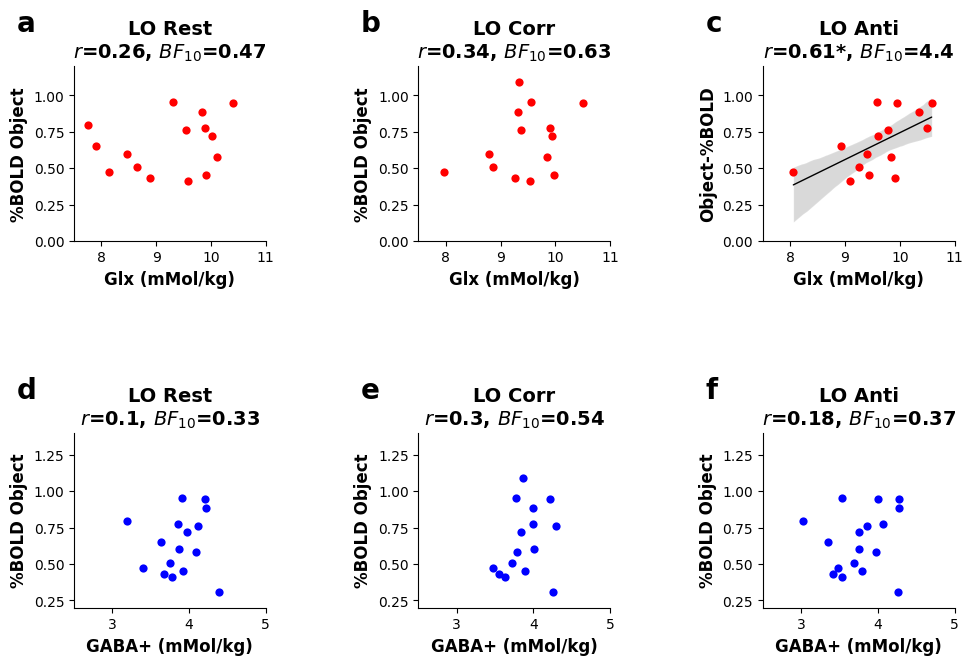

In [40]:
fig, ax =plt.subplots(2,3, figsize = (11,8),constrained_layout=True)

axi = ax.flat
for n, axx in enumerate(axi):
    axx.text(-0.3, 1.2, string.ascii_lowercase[n], transform=axx.transAxes, 
            size=20, weight='bold')

xlims =[7.5,11]
ylims =[0,1.2]

correlationFigpartialcor(dat_frame,'lo_rest_glx_exout','bold','Glx (mMol/kg)','%BOLD Object','LO Rest','two-sided',(0,0),'o','red',xlims,ylims,'lo_rest_fwhm_exout')
correlationFigpartialcor(dat_frame,'lo_corr_glx_exout','bold','Glx (mMol/kg)','%BOLD Object','LO Corr','two-sided',(0,1),'o','red',xlims,ylims,'lo_corr_fwhm_exout')
correlationFigpartialcor(dat_frame,'lo_anti_glx_exout','bold','Glx (mMol/kg)','Object-%BOLD','LO Anti','two-sided',(0,2),'o','red',xlims,ylims,'lo_anti_fwhm_exout')
xlims =[2.5,5]
ylims = [0.2,1.4]
correlationFigpartialcor(dat_frame,'lo_rest_exout','bold','GABA+ (mMol/kg)','%BOLD Object','LO Rest','two-sided',(1,0),'o','blue',xlims,ylims,'lo_rest_fwhm_exout')
correlationFigpartialcor(dat_frame,'lo_corr_exout','bold','GABA+ (mMol/kg)','%BOLD Object','LO Corr','two-sided',(1,1),'o','blue',xlims,ylims,'lo_corr_fwhm_exout')
correlationFigpartialcor(dat_frame,'lo_anti_exout','bold','GABA+ (mMol/kg)','%BOLD Object','LO Anti','two-sided',(1,2),'o','blue',xlims,ylims,'lo_anti_fwhm_exout')

fig.tight_layout(pad=4)


In [41]:
s = pg.partial_corr(data=dat_frame,x='v1_rest_exout',y='bold',x_covar='v1_rest_fwhm_exout')
n=s["n"]
r=s["r"].round(2)
#p=s["p-val"].round(3)
print(s)

          n         r          CI95%     p-val
pearson  17  0.259958  [-0.27, 0.67]  0.330882


(0, 0)
EVC Rest
normal distribution, using pearson
          n         r         CI95%     p-val   BF10     power
pearson  17  0.626413  [0.21, 0.85]  0.007134  8.443  0.804534
n( 17 ) p= 0.007 r= 0.63 pearson 8.44
correcting for spectral quality
*****           n         r         CI95%     p-val
pearson  17  0.628573  [0.19, 0.86]  0.009108
(0, 1)
EVC Corr
normal distribution, using pearson
          n         r        CI95%     p-val  BF10     power
pearson  15  0.647277  [0.2, 0.87]  0.009093  7.12  0.782742
n( 15 ) p= 0.009 r= 0.65 pearson 7.12
correcting for spectral quality
*****           n        r         CI95%     p-val
pearson  15  0.55844  [0.04, 0.84]  0.037933
(0, 2)
EVC Anti
normal distribution, using pearson
          n         r         CI95%    p-val   BF10     power
pearson  15  0.346648  [-0.2, 0.73]  0.20559  0.665  0.251207
n( 15 ) p= 0.206 r= 0.35 pearson 0.66
correcting for spectral quality
*****           n         r          CI95%     p-val
pearson  15  0.361

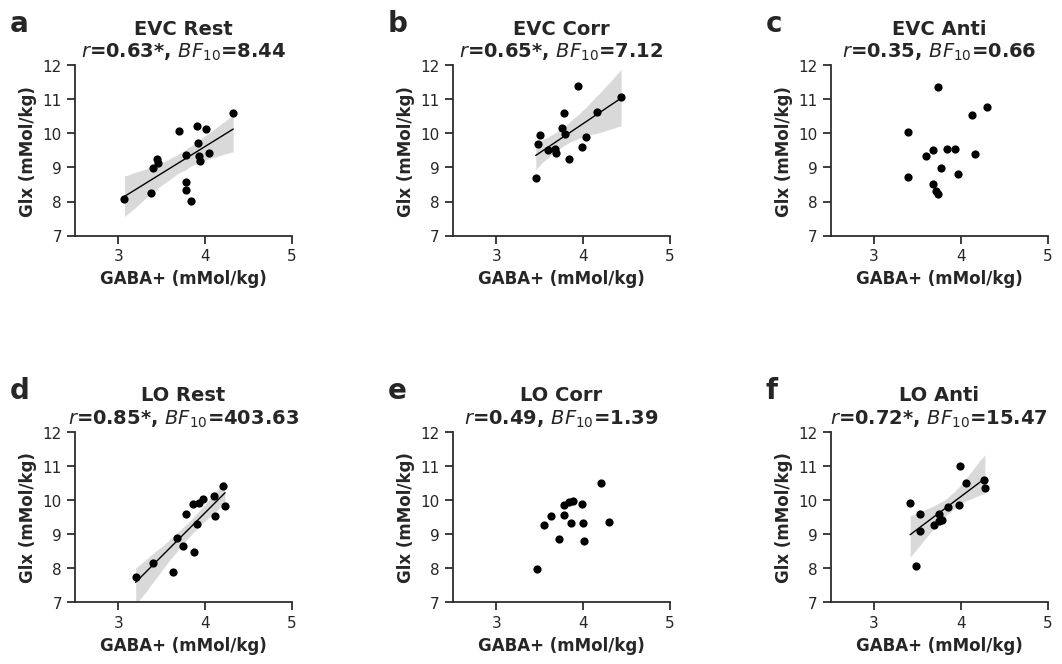

In [42]:
fig, ax =plt.subplots(2,3, figsize = (12,8),constrained_layout=True)

axi = ax.flat
for n, axx in enumerate(axi):
    axx.text(-0.3, 1.2, string.ascii_lowercase[n], transform=axx.transAxes, 
            size=20, weight='bold')


xlims =[2.5,5]
ylims = [7,12]
correlationFigpartialcor(dat_frame,'v1_rest_exout','v1_rest_glx_exout','GABA+ (mMol/kg)','Glx (mMol/kg)','EVC Rest','two-sided',(0,0),'o','black',xlims,ylims,'v1_rest_fwhm_exout')
correlationFigpartialcor(dat_frame,'v1_corr_exout','v1_corr_glx_exout','GABA+ (mMol/kg)','Glx (mMol/kg)','EVC Corr','two-sided',(0,1),'o','black',xlims,ylims,'v1_corr_fwhm_exout')
correlationFigpartialcor(dat_frame,'v1_anti_exout','v1_anti_glx_exout','GABA+ (mMol/kg)','Glx (mMol/kg)','EVC Anti','two-sided',(0,2),'o','black',xlims,ylims,'v1_anti_fwhm_exout')

correlationFigpartialcor(dat_frame,'lo_rest_exout','lo_rest_glx_exout','GABA+ (mMol/kg)','Glx (mMol/kg)','LO Rest','two-sided',(1,0),'o','black',xlims,ylims,'lo_rest_fwhm_exout')
correlationFigpartialcor(dat_frame,'lo_corr_exout','lo_corr_glx_exout','GABA+ (mMol/kg)','Glx (mMol/kg)','LO Corr','two-sided',(1,1),'o','black',xlims,ylims,'lo_corr_fwhm_exout')
correlationFigpartialcor(dat_frame,'lo_anti_exout','lo_anti_glx_exout','GABA+ (mMol/kg)','Glx (mMol/kg)','LO Anti','two-sided',(1,2),'o','black',xlims,ylims,'lo_corr_fwhm_exout')
fig.tight_layout(pad=4)



## average data and compare formally 

In [43]:
mean_values = pd.DataFrame()
mean_values['v1_gaba']=dat_frame[['v1_anti_exout','v1_corr_exout','v1_rest_exout']].mean(axis=1)
mean_values['v1_glx']=dat_frame[['v1_anti_glx_exout','v1_corr_glx_exout','v1_rest_glx_exout']].mean(axis=1)
mean_values['v1_fwhm']=dat_frame[['v1_anti_fwhm_exout','v1_corr_fwhm_exout','v1_rest_fwhm_exout']].mean(axis=1)

mean_values['lo_gaba']=dat_frame[['lo_anti_exout','lo_corr_exout','lo_rest_exout']].mean(axis=1)
mean_values['lo_glx']=dat_frame[['lo_anti_glx_exout','lo_corr_glx_exout','lo_rest_glx_exout']].mean(axis=1)
mean_values['lo_fwhm']=dat_frame[['lo_anti_fwhm_exout','lo_corr_fwhm_exout','lo_rest_fwhm_exout']].mean(axis=1)

v1=pg.partial_corr(data=mean_values,x='v1_glx',y='v1_gaba',y_covar='v1_fwhm')
print(v1)

lo=pg.partial_corr(data=mean_values,x='lo_glx',y='lo_gaba',y_covar='lo_fwhm')
print(lo)

          n         r        CI95%     p-val
pearson  18  0.735381  [0.39, 0.9]  0.000768
          n         r         CI95%     p-val
pearson  17  0.640404  [0.21, 0.86]  0.007529


0
EVC
normal distribution, using pearson
          n        r         CI95%     p-val    BF10     power
pearson  18  0.72526  [0.39, 0.89]  0.000659  61.785  0.952896
n( 18 ) p= 0.001 r= 0.73 pearson 61.78
correcting for spectral quality
*****           n         r        CI95%     p-val
pearson  18  0.735381  [0.39, 0.9]  0.000768
1
LO
normal distribution, using pearson
          n         r         CI95%     p-val      BF10     power
pearson  17  0.841856  [0.61, 0.94]  0.000023  1105.061  0.996776
n( 17 ) p= 0.0 r= 0.84 pearson 1105.06
correcting for spectral quality
*****           n         r         CI95%     p-val
pearson  17  0.640404  [0.21, 0.86]  0.007529


(np.int64(17),
 np.float64(0.0),
 np.float64(0.84),
 'pearson',
 np.float64(1105.06))

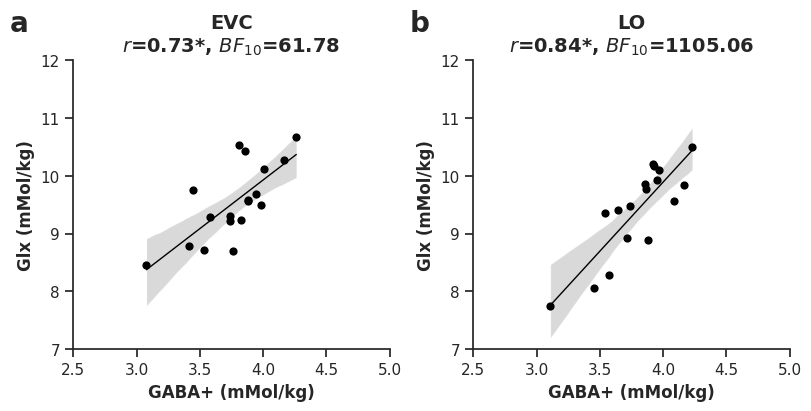

In [44]:
fig, ax =plt.subplots(1,2, figsize = (8,4),constrained_layout=True)

ax = ax.flat
for n, axx in enumerate(ax):
    axx.text(-0.2, 1.1, string.ascii_lowercase[n], transform=axx.transAxes, 
            size=20, weight='bold')

correlationFigpartialcor(mean_values,'v1_gaba','v1_glx','GABA+ (mMol/kg)','Glx (mMol/kg)','EVC','two-sided',(0),'o','black',xlims,ylims,'v1_fwhm')
correlationFigpartialcor(mean_values,'lo_gaba','lo_glx','GABA+ (mMol/kg)','Glx (mMol/kg)','LO','two-sided',(1),'o','black',xlims,ylims,'lo_fwhm')


# Plot the average spectrum for LO and EVC and display in the window below

# Plot correlations between metabolite concentrations x conditions using pearson's correlation so we get a BF readout

### **Visualise** data before and after univariate outlier exclusion

## Create csv file that stores the data in a table to be read by the plot and analyse notebook

## Create a csv file that can be used to analyse conditions x voxel by LMM in R

In [45]:
#data = dat_frame.copy()
#data = data.drop(labels=range(28, 37), axis=0)
#data.to_csv(filepath2)

### End of notebook. Now, analyse data in the next notebook ###